# Question 4: LDA Topic Modelling and pyLDAvis

Flow: load articles, preprocess, chunk, document-term matrix, choose number of topics, fit LDA (4.1), explore topics and distributions (4.1), interactive intertopic distance map (4.2).

Install once if needed: `pip install pyLDAvis`

In [1]:
import glob, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

## Load and preprocess

Same preparation as Question 3: lowercase, letters only, then split each article into chunks of about 200 words so LDA has enough documents.

In [2]:
rows = []
for f in sorted(glob.glob('../data/research_corpus/research_*.txt')):
    with open(f, encoding='utf-8', errors='ignore') as fh:
        rows.append({'article': os.path.basename(f), 'content': fh.read()})
df_articles = pd.DataFrame(rows)

def clean(text):
    text = re.sub(r'[^a-z\s]', ' ', text.lower())
    return re.sub(r'\s+', ' ', text).strip()

df_articles['clean'] = df_articles['content'].apply(clean)

chunks = []
for _, r in df_articles.iterrows():
    words = r['clean'].split()
    for i in range(0, len(words), 200):
        part = words[i:i + 200]
        if len(part) > 50:
            chunks.append((r['article'], ' '.join(part)))
chunks = pd.DataFrame(chunks, columns=['article', 'text'])
print(len(chunks), 'chunks from', df_articles.shape[0], 'articles')

108 chunks from 5 articles


## Document-term matrix

In [3]:
cv = CountVectorizer(stop_words='english', min_df=3, max_df=0.7)
dtm = cv.fit_transform(chunks['text'])
terms = cv.get_feature_names_out()
print(dtm.shape)

(108, 908)


## Choosing the number of topics

We compare perplexity for 2 to 8 topics (lower is better) as a guide, then also judge how interpretable and distinct the topics are. The earlier 5-topic model had two overlapping topics, so we check whether a smaller number fits better.

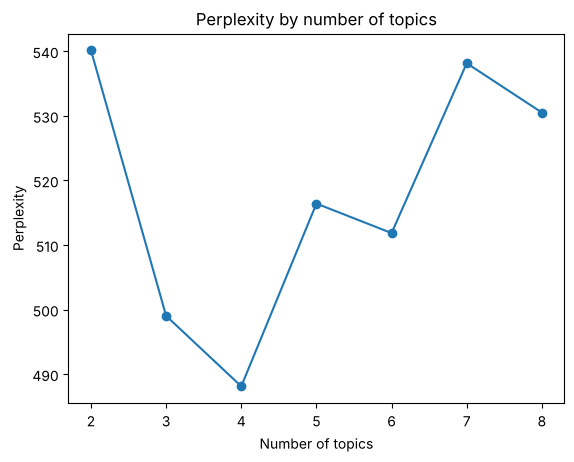

In [4]:
ks = range(2, 9)
perp = []
for k in ks:
    m = LatentDirichletAllocation(n_components=k, random_state=42, max_iter=50).fit(dtm)
    perp.append(m.perplexity(dtm))
plt.plot(list(ks), perp, marker='o')
plt.xlabel('Number of topics'); plt.ylabel('Perplexity')
plt.title('Perplexity by number of topics')
plt.show()

In [5]:
N_TOPICS = 4   # chosen: gives four distinct themes without the overlapping pair seen at 5
lda = LatentDirichletAllocation(n_components=N_TOPICS, random_state=42, max_iter=50, learning_method='batch')
lda.fit(dtm)

,"n_components n_components: int, default=10Number of topics... versionchanged:: 0.19 ``n_topics`` was renamed to ``n_components``",4
,"max_iter max_iter: int, default=10The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the :meth:`fit` method, and not the:meth:`partial_fit` method.",50
,"random_state random_state: int, RandomState instance or None, default=NonePass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"doc_topic_prior doc_topic_prior: float, default=NonePrior of document topic distribution `theta`. If the value is None,defaults to `1 / n_components`.In [1]_, this is called `alpha`.",None
,"topic_word_prior topic_word_prior: float, default=NonePrior of topic word distribution `beta`. If the value is None, defaultsto `1 / n_components`.In [1]_, this is called `eta`.",None
,"learning_method learning_method: {'batch', 'online'}, default='batch'Method used to update `_component`. Only used in :meth:`fit` method.In general, if the data size is large, the online update will be muchfaster than the batch update.Valid options:- 'batch': Batch variational Bayes method. Use all training data in each EM update. Old `components_` will be overwritten in each iteration.- 'online': Online variational Bayes method. In each EM update, use mini-batch of training data to update the ``components_`` variable incrementally. The learning rate is controlled by the ``learning_decay`` and the ``learning_offset`` parameters... versionchanged:: 0.20 The default learning method is now ``""batch""``.",'batch'
,"learning_decay learning_decay: float, default=0.7It is a parameter that control learning rate in the online learningmethod. The value should be set between (0.5, 1.0] to guaranteeasymptotic convergence. When the value is 0.0 and batch_size is``n_samples``, the update method is same as batch learning. In theliterature, this is called kappa.",0.7
,"learning_offset learning_offset: float, default=10.0A (positive) parameter that downweights early iterations in onlinelearning. It should be greater than 1.0. In the literature, this iscalled tau_0.",10.0
,"batch_size batch_size: int, default=128Number of documents to use in each EM iteration. Only used in onlinelearning.",128
,"evaluate_every evaluate_every: int, default=-1How often to evaluate perplexity. Only used in `fit` method.set it to 0 or negative number to not evaluate perplexity intraining at all. Evaluating perplexity can help you check convergencein training process, but it will also increase total training time.Evaluating perplexity in every iteration might increase training timeup to two-fold.",-1
,"total_samples total_samples: int, default=1e6Total number of documents. Only used in the :meth:`partial_fit` method.",1000000.0


## 4.1 Topics: words and their distribution

Top 10 words per topic with their probability within the topic.

In [6]:
topic_word = lda.components_ / lda.components_.sum(axis=1)[:, None]   # P(word | topic)
top_n = 10
for i in range(N_TOPICS):
    idx = topic_word[i].argsort()[::-1][:top_n]
    print(f'Topic {i}:')
    print('   ' + ', '.join(f'{terms[j]} ({topic_word[i][j]:.3f})' for j in idx))

Topic 0:
   data (0.036), triangulation (0.026), methods (0.023), researchers (0.021), qualitative (0.020), study (0.019), researcher (0.013), use (0.012), mixed (0.011), social (0.011)
Topic 1:
   qualitative (0.027), mixed (0.026), reflexivity (0.020), methods (0.019), researcher (0.018), quantitative (0.016), purists (0.012), reality (0.011), guba (0.009), researchers (0.009)
Topic 2:
   development (0.049), developmental (0.027), design (0.027), instructional (0.023), process (0.023), evaluation (0.017), field (0.015), knowledge (0.013), type (0.011), study (0.010)
Topic 3:
   alpha (0.046), cronbach (0.025), instrument (0.022), science (0.021), reliability (0.019), values (0.014), items (0.014), education (0.013), authors (0.012), scales (0.011)


In [7]:
topic_table = pd.DataFrame({
    f'Topic {i}': [terms[j] for j in topic_word[i].argsort()[::-1][:top_n]] for i in range(N_TOPICS)
})
topic_table.index = range(1, top_n + 1)
topic_table

,Topic 0,Topic 1,Topic 2,Topic 3
1,data,qualitative,development,alpha
2,triangulation,mixed,developmental,cronbach
3,methods,reflexivity,design,instrument
4,researchers,methods,instructional,science
5,qualitative,researcher,process,reliability
6,study,quantitative,evaluation,values
7,researcher,purists,field,items
8,use,reality,knowledge,education
9,mixed,guba,type,authors
10,social,researchers,study,scales


### Visualisation: top words per topic

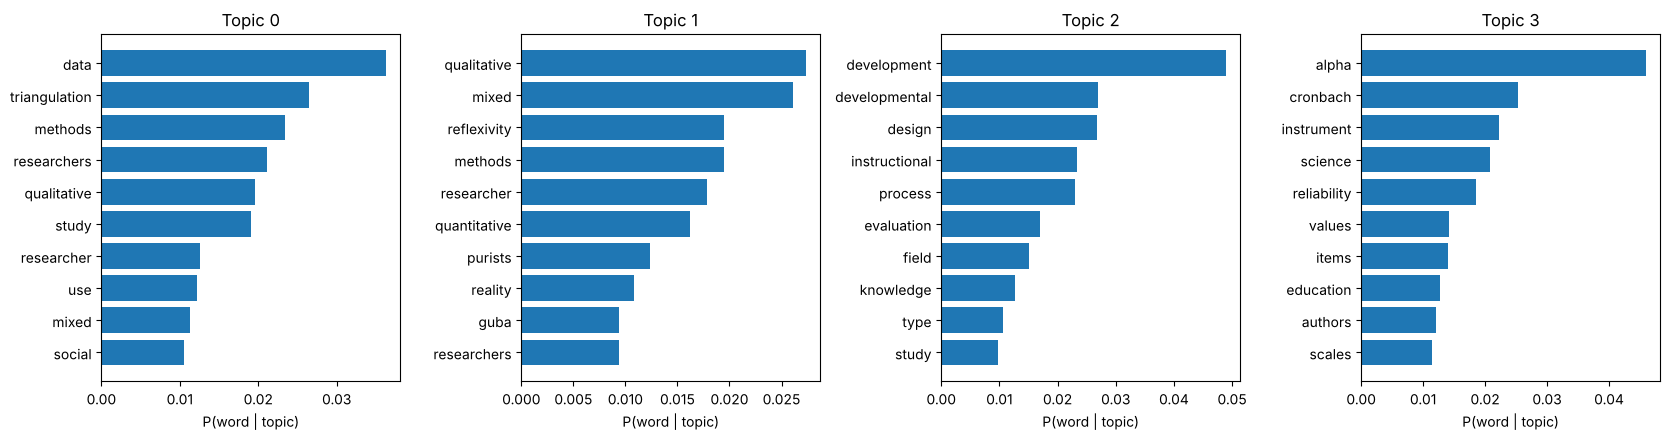

In [8]:
fig, axes = plt.subplots(1, N_TOPICS, figsize=(4.2 * N_TOPICS, 4.5), sharex=False)
for i, ax in enumerate(np.atleast_1d(axes)):
    idx = topic_word[i].argsort()[::-1][:top_n]
    ax.barh([terms[j] for j in idx][::-1], topic_word[i][idx][::-1])
    ax.set_title(f'Topic {i}')
    ax.set_xlabel('P(word | topic)')
plt.tight_layout()
plt.show()

### Visualisation: topic distribution across documents

Average topic mix for each article, and the overall share of each topic in the corpus.

                Topic 0  Topic 1  Topic 2  Topic 3
article                                           
research_1.txt    0.406    0.552    0.018    0.024
research_2.txt    0.606    0.310    0.053    0.031
research_3.txt    0.010    0.010    0.976    0.004
research_4.txt    0.003    0.004    0.021    0.971
research_5.txt    0.972    0.012    0.010    0.006


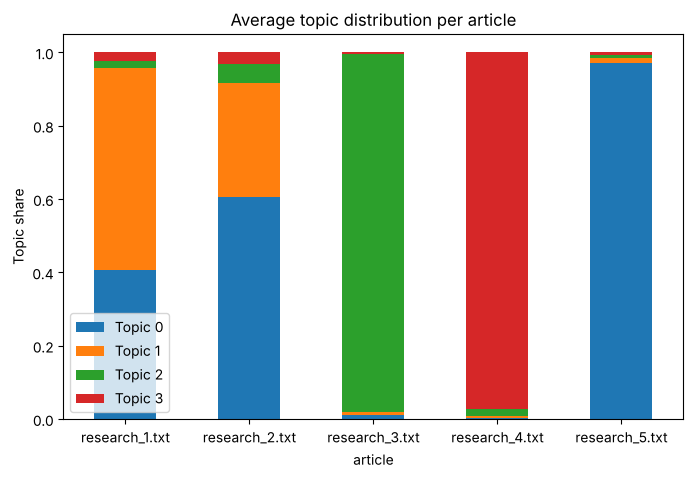

In [9]:
doc_topic = lda.transform(dtm)                       # P(topic | chunk)
dt = pd.DataFrame(doc_topic, columns=[f'Topic {i}' for i in range(N_TOPICS)])
dt['article'] = chunks['article'].values
per_article = dt.groupby('article').mean()
print(per_article.round(3))
per_article.plot(kind='bar', stacked=True, figsize=(8, 5), title='Average topic distribution per article')
plt.ylabel('Topic share'); plt.xticks(rotation=0)
plt.show()

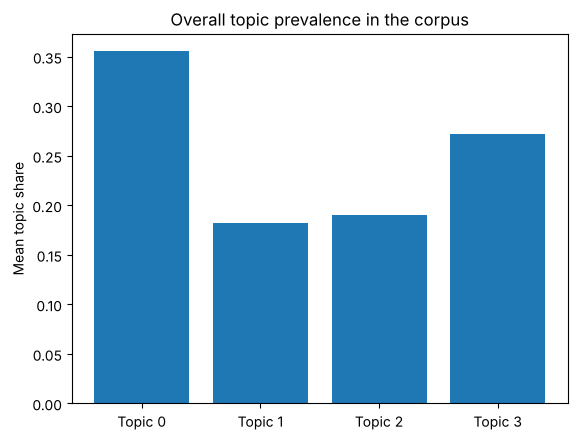

In [10]:
overall = doc_topic.mean(axis=0)
plt.bar([f'Topic {i}' for i in range(N_TOPICS)], overall)
plt.title('Overall topic prevalence in the corpus'); plt.ylabel('Mean topic share')
plt.show()

In [11]:
chunks['dominant_topic'] = doc_topic.argmax(axis=1)
pd.crosstab(chunks['article'], chunks['dominant_topic'])

dominant_topic,0,1,2,3
article,,,,
research_1.txt,14,14,0,0
research_2.txt,10,2,0,0
research_3.txt,0,0,19,0
research_4.txt,0,0,0,29
research_5.txt,20,0,0,0


### Topic labels (interpretation)

Replace these with your own wording after checking the word lists above.

In [12]:
print(topic_table.to_string())

          Topic 0       Topic 1        Topic 2      Topic 3
1            data   qualitative    development        alpha
2   triangulation         mixed  developmental     cronbach
3         methods   reflexivity         design   instrument
4     researchers       methods  instructional      science
5     qualitative    researcher        process  reliability
6           study  quantitative     evaluation       values
7      researcher       purists          field        items
8             use       reality      knowledge    education
9           mixed          guba           type      authors
10         social   researchers          study       scales


## 4.2 Intertopic Distance Map (pyLDAvis)

Bubbles are topics, placed by the similarity of their word distributions (distance map). Bubble size shows prevalence. Selecting a topic shows its most salient words; the lambda slider balances word frequency against how specific a word is to the topic.

In [13]:
import pyLDAvis
import pyLDAvis.lda_model

pyLDAvis.enable_notebook()
vis = pyLDAvis.lda_model.prepare(lda, dtm, cv, mds='mmds', sort_topics=False)
vis

/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_mds.py:735: FutureWarning: The default value of `init` will change from 'random' to 'classical_mds' in 1.10. To suppress this warning, provide some value of `init`.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/manifold/_mds.py:752: FutureWarning: The `dissimilarity` parameter is deprecated and will be removed in 1.10. Use `metric` instead.
  warnings.warn(


PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.177104  0.036935       1        1  34.947720
1      0.113360 -0.172841       2        1  18.136701
2     -0.194453 -0.083872       3        1  18.292062
3     -0.096011  0.219778       4        1  28.623518, topic_info=              Term        Freq       Total Category  logprob  loglift
27           alpha  108.000000  108.000000  Default  30.0000  30.0000
214    development   83.000000   83.000000  Default  29.0000  29.0000
187           data  113.000000  113.000000  Default  28.0000  28.0000
856  triangulation   77.000000   77.000000  Default  27.0000  27.0000
215  developmental   40.000000   40.000000  Default  26.0000  26.0000
..             ...         ...         ...      ...      ...      ...
455      knowledge   21.722935   54.643910   Topic4  -4.6822   0.3285
222      different   17.787529   36.117820   Topic4  -4.8821   0.5427
799          study   25.274823   99.970351   Topic4  -4.5308  -0.1241
796       students   15.723359   30.120088   Topic4  -5.0054   0.6009
871            use   13.624208   59.157797   Topic4  -5.1487  -0.2174

[244 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
4         4  0.976436  acceptable
8         3  0.710747  activities
8         4  0.142149  activities
18        2  0.950852     advance
19        2  0.912150    advocate
...     ...       ...         ...
882       4  0.771852      values
892       4  0.899354      volume
895       2  0.912148        wars
904       2  0.815574     writing
906       4  0.977441        year

[339 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4])

In [14]:
# Standalone interactive file to include in the repo / submission
os.makedirs('../docs', exist_ok=True)
pyLDAvis.save_html(vis, '../docs/lda_intertopic_map.html')
print('Saved ../docs/lda_intertopic_map.html')

Saved ../docs/lda_intertopic_map.html
